Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.stem import LancasterStemmer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.sparse import csr_matrix

In [2]:
PCA_number_components=2500 #still need to tuned
numberStopwords=50
stemmization_Flag=True
lemmization_Flag=True

Load data

In [3]:
train_data = pd.read_csv("data_supervised.csv", encoding="utf8")
target = pd.read_csv("target_supervised.csv", encoding="utf8")
unsupervised_data=pd.read_csv("data_unsupervised.csv", encoding="utf8")
#for each dataset we print for each column the number of elements missing
print(train_data.isnull().sum())
print(target.isnull().sum())
print(unsupervised_data.isnull().sum())


author         0
subreddit      0
created_utc    0
body           0
dtype: int64
author    0
gender    0
dtype: int64
author         0
subreddit      0
created_utc    0
body           2
dtype: int64


Only unsupervised_data.csv has 2 comments missing
deletion of the missing comments

In [4]:
unsupervised_data=unsupervised_data.dropna()
print(unsupervised_data.isnull().sum())

author         0
subreddit      0
created_utc    0
body           0
dtype: int64


Count duplicates

In [5]:
print(train_data.duplicated().sum())
print(unsupervised_data.duplicated().sum())  
print(target.duplicated().sum())  

7
256137
0


Deletion of duplicated rows

In [6]:
train_data=train_data.drop_duplicates()
unsupervised_data=unsupervised_data.drop_duplicates()
print(train_data.duplicated().sum())
print(unsupervised_data.duplicated().sum())  
print(target.duplicated().sum())  

0
0
0


Empirical distribution of the number of characterst in each comment

train data


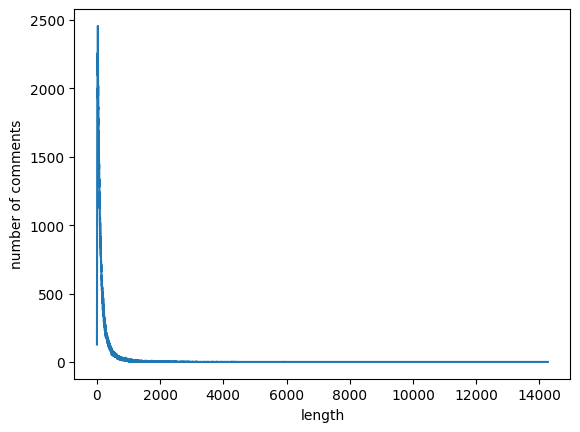

filtered train data


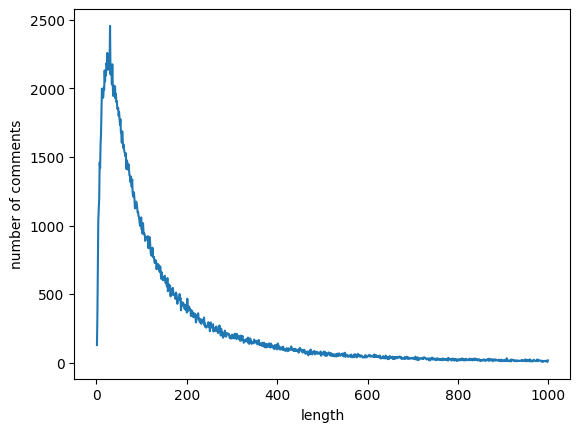

unsupervised data


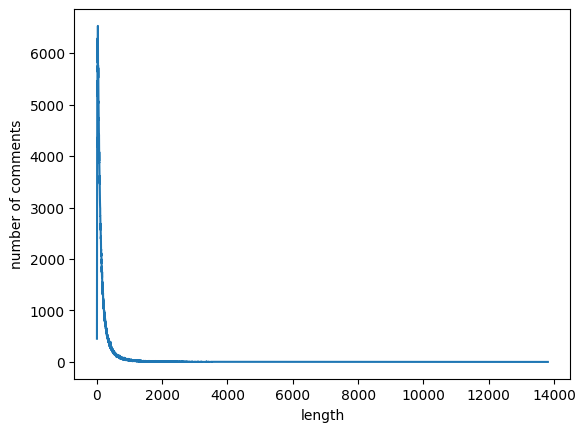

filtered unsupervised data


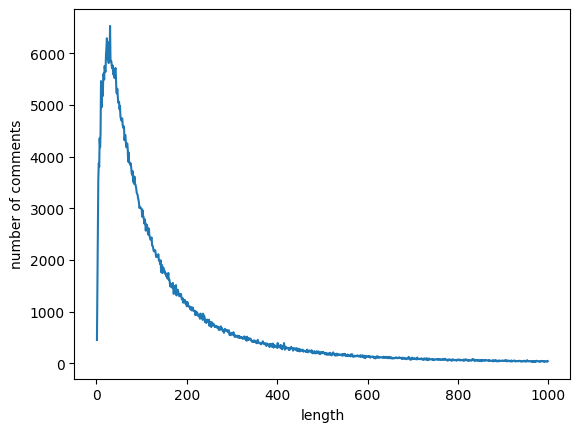

In [8]:
def plotEmpiricalDistributionNumberOfComments(data):

    #we can define a series that has the length as an index and the number of comments that match the length as the value
    countForLenght=data.groupby('length').count()['body']

    #print(countForLenght.max)

    x = countForLenght.index
    y =  countForLenght.values

    df = pd.DataFrame({
        'length' : x, #'length' : x[0:1000], 
        'number of comments' : y#[0:1000]
    })

    plt.figure()
    sns.lineplot(
        data = df, # which dataframe you want to use as the source data
        x = 'length', # which column to use for x-axis
        y = 'number of comments', # which column to use for y-axis
        ax = plt.gca() # assign this plot to current axis, not mandatory in this case
    )
    plt.show()

train_data['length'] = train_data['body'].astype(str).apply(len)
unsupervised_data['length'] = unsupervised_data['body'].astype(str).apply(len)

print("train data")
plotEmpiricalDistributionNumberOfComments(train_data)
print("filtered train data")
plotEmpiricalDistributionNumberOfComments(train_data[train_data['length'] < 1000])
print("unsupervised data")
plotEmpiricalDistributionNumberOfComments(unsupervised_data)
print("filtered unsupervised data")
plotEmpiricalDistributionNumberOfComments(unsupervised_data[unsupervised_data['length'] < 1000])


distribution of the number of comments per author

In [24]:
#save DF as csv
unsupervised_data.groupby('author').count().to_csv("number_of_comments_per_author_unsupervised.csv", index=False)

train data author distribution without outliers


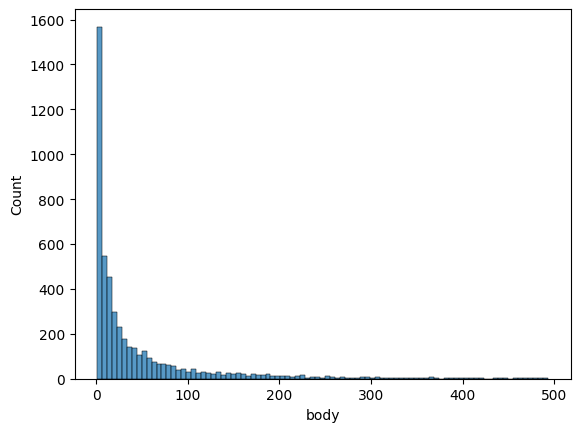

unsupervised data author distribution without outliers


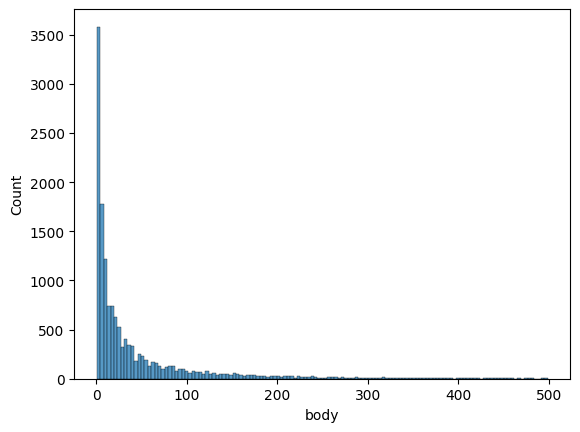

In [9]:
print("train data author distribution without outliers")
plt.figure()
sns.histplot(
    train_data.groupby('author').count()['body'][train_data.groupby('author').count()['body'] < 500]
)
plt.show()

print("unsupervised data author distribution without outliers")
plt.figure()
sns.histplot(
    unsupervised_data.groupby('author').count()['body'][unsupervised_data.groupby('author').count()['body'] < 500]
)
plt.show()


In [10]:
#printing the number of males and females
print(target.groupby('gender').count())

#printing the number of comments for males and females
print(pd.merge(target,train_data).groupby('gender').count())

        author
gender        
0         3651
1         1349
        author  subreddit  created_utc    body  length
gender                                                
0       228651     228651       228651  228651  228651
1        67384      67384        67384   67384   67384


In [11]:
train_data=train_data.map(lambda x: x.lower() if isinstance(x, str) else x)
target=target.map(lambda x: x.lower() if isinstance(x, str) else x)
unsupervised_data=unsupervised_data.map(lambda x: x.lower() if isinstance(x, str) else x)


In [7]:
#train_data['body'].str.split().explode()

MostFrequentWords = train_data['body'].str.split().explode().value_counts()[0:numberStopwords].index.tolist()
print(MostFrequentWords)
for word in MostFrequentWords:
    train_data['body']=train_data['body'].str.replace(rf'\b{word}\b', '', regex=True)
MostFrequentWords = train_data['body'].str.split().explode().value_counts()[0:numberStopwords].index.tolist()
print(MostFrequentWords)


['the', 'to', 'a', 'I', 'and', 'of', 'you', 'that', 'is', 'in', 'it', 'for', 'have', 'with', 'be', 'on', 'but', 'was', 'are', 'my', 'not', 'as', 'like', 'just', 'your', 'or', 'this', 'they', 'if', 'at', 'so', "I'm", 'about', 'can', "don't", 'would', 'get', 'do', 'an', "it's", 'me', 'he', 'from', 'The', 'what', 'all', 'more', 'people', 'one', 'out']
['.', "'s", ',', "'m", 'think', 'up', 'when', 'because', 'some', 'really', "'re", 'will', 'we', 'had', 'who', 'than', 'how', 'by', 'know', 'has', 'their', 'If', 'them', 'his', 'You', 'there', 'It', 'no', 'only', "It's", 'her', "'ve", 'make', 'other', 'want', 'much', 'even', 'were', 'been', 'then', 'good', 'time', 'being', 'could', '(', 'she', 'see', 'any', 'into', 'go']


In [13]:
#lemmization

# Function to tokenize and lemmatize a single text
def lemmatize_text(text,lemmatizer):
    # Tokenize the text into words
    tokens = word_tokenize(text)
    
    # Lemmatize each token
    lemmatized_words = []
    for word in tokens:
        lemmatized_word = lemmatizer.lemmatize(word)
        lemmatized_words.append(lemmatized_word)
    
    # Join the lemmatized words back into a single string
    lemmatized_text = ' '.join(lemmatized_words)
    return lemmatized_text

def lemmization(df):
    # Initialize the lemmatizer
    lemmatizer = WordNetLemmatizer()

    # Apply the lemmatization function to the DataFrame column
    for index, row in train_data.iterrows():
        lemmatized_result = lemmatize_text(row['body'],lemmatizer)  # Process each row
        df.at[index, 'body'] = lemmatized_result

if lemmization_Flag:
    lemmization(train_data)

In [14]:
# Print the resulting DataFrame
print(train_data['body'][0])

think 'd nearly much fanfiction picture shipping ban-ban lyro . saying .


In [15]:
#stemming
def stemmer_text(text,stemmer):
    # Tokenize the text into words
    tokens = word_tokenize(text)
    #tokens = text.split(' ')#what if we don't tokenize?
    stemmer_words = []
    for word in tokens: 
        stemmer_words.append(stemmer.stem(word))
    
    stemmed_text = ' '.join(stemmer_words)
    return stemmed_text

def stemmization(df):
    stemmer = LancasterStemmer()

    for index, row in train_data.iterrows():
        stemmed_result = stemmer_text(row['body'],stemmer)  # Process each row
        df.at[index, 'body'] = stemmed_result

if stemmization_Flag:
    stemmization(train_data)

In [16]:
print(train_data['body'][0])

think 'd near much fanfict pict ship ban-b lyro . say .


In [17]:
#grouping by the author
#TODO controllare se sta roba serve
train_data=train_data[['author','body']].groupby('author').agg(' '.join).reset_index()

vectorizerCount = CountVectorizer()
vectorizerCount.fit(train_data['body'])
print(sorted(vectorizerCount.vocabulary_))
vectorizerCount = vectorizerCount.transform(train_data['body'])

['00', '000', '0000', '000000', '00000000', '0000000000001', '0000000000011885195904108', '000000000055055104011504511400', '0000000001', '0000000010001001100000010000001100000100100010000', '00000001', '00000001c', '00000002', '00000006434', '0000001', '00000014', '00000018', '00000043', '00000044', '00000066', '000001', '0000011875', '000002', '00000252', '00000385', '00000400', '000007', '00000aab0f6c', '00001', '000018', '000029038', '00008699196', '00009', '0001', '0001778km', '0002', '000287722', '00033', '0005', '000955', '000a', '000e', '000gb', '000gp', '000ish', '000k', '000km', '000lb', '000lbs', '000m', '000mcg', '000mg', '000mw', '000rpm', '000sek', '000u6', '000won', '001', '00100000', '00100111', '00101110', '0010146725', '0011', '0014', '00147767', '00162', '0017', '001916', '0019bb30f31a', '001b2166becc', '001b2166c62d', '002', '0022', '002219319097', '002450171', '002513', '002530x', '0028390875900994', '002880', '0029', '002926', '002950', '002main', '003', '003049',

In [18]:
print(vectorizerCount.shape)
#print(csr_matrix(vectorizerCount.toarray()))
#print(len(vectorizerCount.vocabulary_))


(5000, 118497)


In [19]:
vectorizerTfidf = TfidfVectorizer()
vectorizerTfidf.fit(train_data['body'])
#print(sorted(vectorizerTfidf.vocabulary_))
vectorizerTfidf = vectorizerTfidf.transform(train_data['body'])

#vectorizerTfidf.fit(unsupervised_data['body'])
#print(sorted(vectorizerTfidf.vocabulary_))
#vectorizerTfidf = vectorizerTfidf.transform(unsupervised_data['body']))

In [20]:
#print(csr_matrix(vectorizerTfidf.toarray()))
#boh = vectorizerTfidf.toarray()

4. Reduce the complexity of your dataset.

In [21]:
pca=PCA(n_components=PCA_number_components,random_state=42,)
pca.fit(vectorizerTfidf)


KeyboardInterrupt: 

<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_24390/3955325369.py:18: SyntaxWarning: invalid escape sequence '\s'
  plt.title(f'{(PCA_number_components/2)-1} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)], 2)}% of $\sigma^2$')


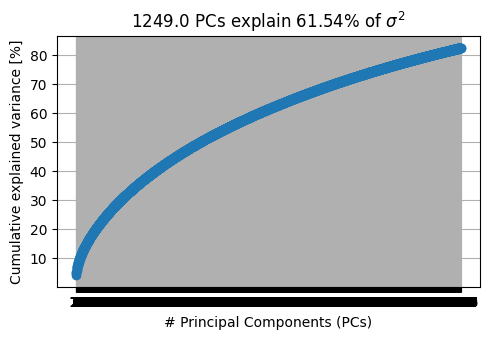

82.61302426034729


In [ ]:
# describe how much of the dataset variability is indicated by a given amount of features
explained_variance = pca.explained_variance_ratio_

# evaluate the total dataset variability while increasing the variables
cumul_exp_var = np.cumsum(explained_variance)

# percentage value to better understand the best number of components
perc_cumul_exp_var = cumul_exp_var * 100

# make the plot of cumulative explained variance wrt number of components

plt.figure(figsize=(5, 3.5))
plt.plot(perc_cumul_exp_var, marker='o')
plt.xlabel('# Principal Components (PCs)')
plt.ylabel('Cumulative explained variance [%]')
plt.xticks([i for i in range(PCA_number_components)], [i for i in range(1,PCA_number_components+1)])
plt.grid()
plt.title(f'{(PCA_number_components/2)-1} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)], 2)}% of $\sigma^2$')
plt.tight_layout()
plt.show()

print(perc_cumul_exp_var[-1])
pca_result = pca.transform(vectorizerTfidf)

dfPCA=pd.DataFrame(pca_result)
dfPCA.to_csv("PCA.csv")